In [1]:
from scipy.io import loadmat
import matplotlib.pyplot as plt
import numpy as np

In [2]:
analytic = loadmat('C:/Users/au646858/Downloads/falk1run/analytic.mat')
resistivity = loadmat('C:/Users/au646858/Downloads/falk1run/resistivities.mat')['resies']
dbdt0 = analytic['Analytic'][0][0][0][0][0][0].squeeze().T
time  = analytic['Analytic'][0][0][0][0][0][1].squeeze()

In [3]:
dbdt0 = analytic['Analytic'][0][0][0][0][0][0].squeeze().T
time  = analytic['Analytic'][0][0][0][0][0][1].squeeze()

In [4]:
time

array([2.190e-06, 5.190e-06, 7.190e-06, 9.190e-06, 1.119e-05, 1.319e-05,
       1.519e-05, 1.719e-05, 1.919e-05, 2.119e-05, 2.369e-05, 2.669e-05,
       3.019e-05, 3.469e-05, 4.069e-05, 4.819e-05, 5.719e-05, 6.869e-05,
       8.319e-05, 1.017e-04, 1.252e-04, 1.542e-04, 1.912e-04, 2.377e-04,
       2.957e-04, 3.692e-04, 4.617e-04, 5.782e-04, 7.247e-04, 9.092e-04])

In [5]:
anemone = loadmat('C:/Users/au646858/Downloads/falk1run/anemone.mat')
dbdt = anemone['SimPEG'][0][0][0][0][0][0].squeeze().T

In [6]:
tx = Loop.circle(1)
rx = Receiver()
t = torch.from_numpy(time)

res = torch.from_numpy(np.repeat(resistivity[np.newaxis, :], 2, axis=0)).squeeze()
thk = torch.from_numpy(np.ones(resistivity.shape)*1.)

fwr = Forward(tx, rx, t)
dbdt1 = fwr(res,thk).real.T / c.pi

NameError: name 'Loop' is not defined

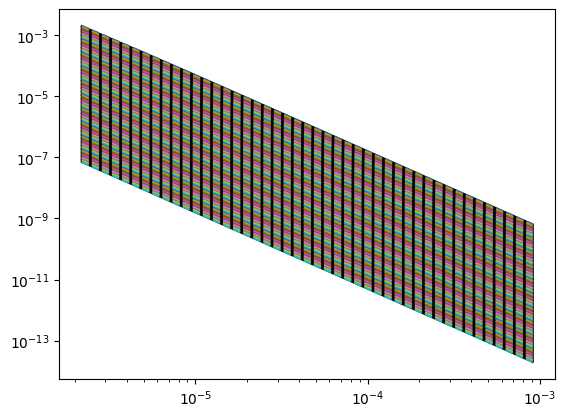

In [ ]:
plt.figure()
plt.loglog(time, dbdt0, 'k-');
plt.loglog(time, dbdt1, '--');

In [7]:
import torch
from anemone import constants as c

def dbdt_center_of_circular_loop_halfspace(time, rho, r):
    sigma = 1./rho
    tau = r*torch.sqrt(0.25*sigma*c.mu0/time)
    term1 = 3.0*torch.erf(tau)
    term2 = (2.0/c.sqrt_pi)*tau*(3.0 + 2.0*tau**2)*torch.exp(-tau**2)
    dbdt = (term1 - term2)/(sigma*r**3)#/(torch.pi*r**2)
    return dbdt

In [14]:
from anemone.forwards import ForwardFlow, Forward, gating_matrix, wv_to_t, invFourier, rte, drte_dsigma
from anemone.transforms import *

def rte_halfspace(sigma, omega, wave_length, mu=c.mu0, epsilon=c.epsilon0):
    if isinstance(mu, float):
        mu = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*mu
    if isinstance(epsilon, float):
        epsilon = torch.ones_like(sigma, dtype=torch.complex128, device=sigma.device)*epsilon
    
    u = torch.sqrt(1. + 1j*sigma*mu*omega/wave_length**2)
    rte = (1 - u) / (1 + u)
    return torch.nan_to_num(rte)


class ForwardFlow(Forward):
    geomz = None
    t2t   = None

    def __init__(self, source, receiver, times, waveform=None, filterfunc=None, t_end=None, tolerance=None):
        super().__init__(source, receiver, times, waveform, filterfunc, t_end, tolerance)
        self.t2t = None

    def forward(self):
        def frq_integrand(f):
            self.omega = c.twopi*f[None,:,None]
            def wvlngth_integrand(wave_length):
                """ Hz from horizontal electric dipole. """
                self.lmb = wave_length[None, None, :]          
                self.sfield_rte = torch.exp(-self.lmb*self.sfield_dz)*self.lmb / c.fourpi
                # intg = rte(self.sigma, self.thick, self.omega, self.lmb)*self.sfield_rte
                intg = rte_halfspace(self.sigma[:1], self.omega, self.lmb)*self.sfield_rte

                return intg.squeeze()
            if self.geomz is None:
                hkl1 = Hankel(wvlngth_integrand, 1, device=self.device)
                def geomz_r(r):
                    return self.source.geomz(self.receiver, r).to(torch.double).to(self.device)
                Hr, self.geomz, self.lmb = hkl1.preintegrate(geomz_r, self.rmin, self.rmax)

            else:
                Hr = torch.einsum('...i,i->...', wvlngth_integrand(self.lmb.squeeze()), self.geomz)
            if self.filterfunc is not None:
                Hr *= self.filterfunc.omega_filter(self.omega.squeeze())
            if self.waveform is not None:
                Hr /= -1j*self.omega.squeeze()
            return Hr.squeeze()
        
        if self.t2t is None:
            self.cbft=invFourier(frq_integrand, device=self.device, tolerance=self.tolerance)
            def t2t_func(t_in):
                if self.t_end is not None:
                    waveform_matrix = wv_to_t(t_in, t_in, waveform=self.waveform)
                    gate_matrix = gating_matrix(t_in, self.t_st, self.t_end, n_eval=1000)
                    return gate_matrix @ waveform_matrix
                else:
                    return wv_to_t(self.times, t_in, waveform=self.waveform)

            
            Ht, self.t2t, self.omega1 = self.cbft.preintegrate(t2t_func, self.tmin, self.tmax)
            # self.t2t *= self.omega1[None, :]
        else:
            Ht = torch.einsum('ij,...j->...i', self.t2t, self.cbft.f1(self.omega1.squeeze()))
        self.dpred = Ht.real
        return self.dpred

In [15]:

from anemone.system import Loop, Receiver, Waveform, FilterChain, ButterworthFilter
import numpy as np
import torch
import matplotlib.pyplot as plt
from anemone import constants as c

# time = np.logspace(-9, -2, 101)


#radius = torch.from_numpy(np.ones(1)*np.sqrt(1./np.pi))
radius = 1.
# r = radius*(2*np.pi/(n*np.sin(2*np.pi/n)))**0.5
# r = radius
# t = torch.linspace(0, 2*torch.pi, n)
# x = r*torch.cos(t)
# y = r*torch.sin(t)
# z = torch.ones_like(x)*0.
# lp = Loop(x, y, z)
# lp.area = torch.pi*radius**2
# lp.radius = r
# tx = lp

tx = Loop.circle(torch.ones(1)*radius)
# tx = Loop.square(radius*c.sqrt_pi)
rx = Receiver()

res = torch.from_numpy(np.repeat(resistivity[np.newaxis, :], 2, axis=0)).squeeze()
thk = torch.from_numpy(np.ones(resistivity.shape)*1.)


fwr = ForwardFlow(tx, rx, torch.from_numpy(time))
dbdt = fwr(res, thk).numpy().real.T
dbdt /= c.pi*radius**2

# from anemone.physics import hzdt_halfspace_center_circle_loop as fwr
# dbdt  = fwr(torch.from_numpy(time[:, None]), torch.from_numpy(resistivity), radius).numpy()*4.*np.pi*1e-7
#dbdt = dbdt_center_of_circular_loop_halfspace(torch.from_numpy(time[:, None]), torch.from_numpy(resistivity), radius).numpy()/c.pi*radius**2
# dbdt0 = get_analytic_tdem_circLoop(time, resistivity.squeeze(), radius).T

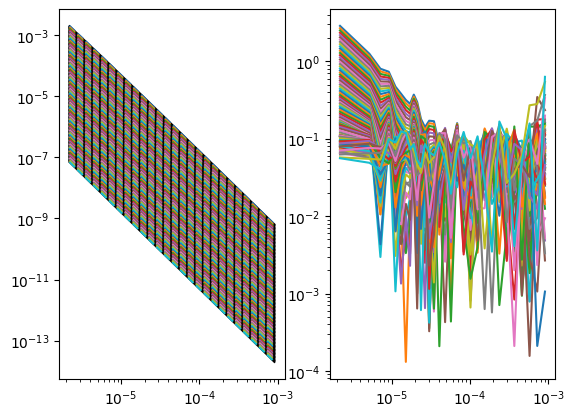

In [16]:
rel_error = np.abs((dbdt - dbdt0)/dbdt0)
fig,axs = plt.subplots(1,2)
axs[0].loglog(time, dbdt0, 'k-')
axs[0].loglog(time, dbdt, '--')
axs[1].loglog(time, rel_error*100);